In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
df = pd.read_csv(url)

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [2]:
print(df.shape)
df.info()

(20640, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [3]:
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [4]:
median_value = df["total_bedrooms"].median()
df["total_bedrooms"] = df["total_bedrooms"].fillna(median_value)

df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


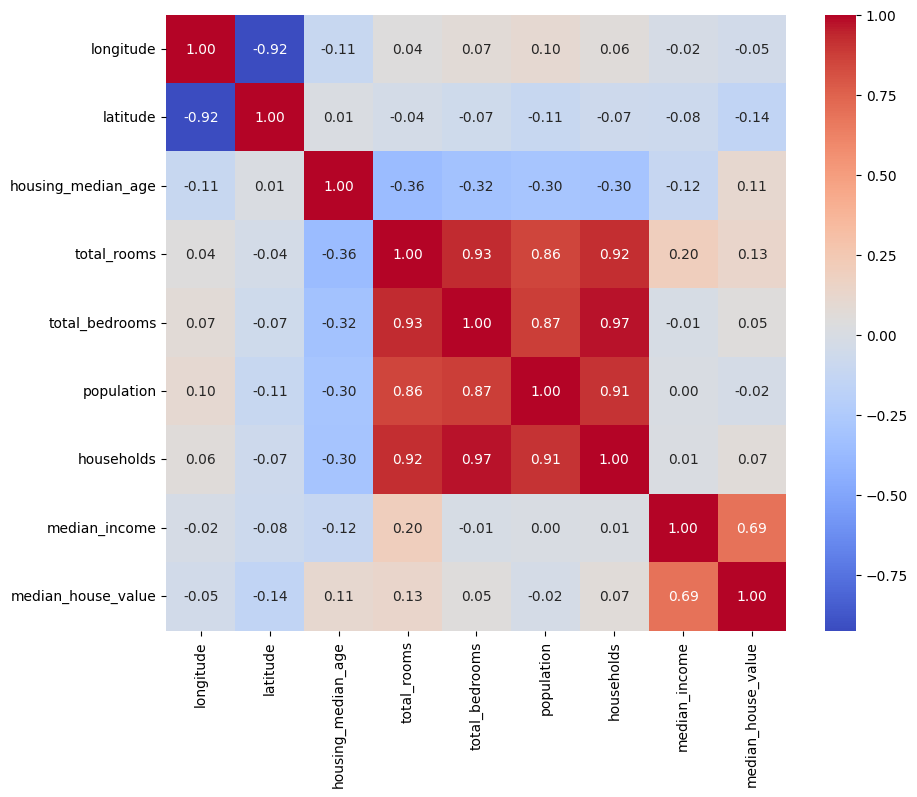

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

corr = df.drop(columns="ocean_proximity").corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Nayi (interaction) features
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]
df["income_x_rooms"] = df["median_income"] * df["rooms_per_household"]

# 2. Text column ko numbers mein badlo
df = pd.get_dummies(df, columns=["ocean_proximity"], drop_first=True, dtype=int)

# 3. X (inputs) aur y (jo predict karna hai)
X = df.drop(columns="median_house_value")
y = df["median_house_value"]

# 4. Train / test split (80% seekhne ke liye, 20% test ke liye)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Standardize (sab columns ko same scale par lao)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print(X_train_s.shape, X_test_s.shape)

(16512, 16) (4128, 16)


In [8]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

alphas = {"alpha": [0.01, 0.1, 1, 10, 100, 1000]}

# 1. OLS (koi alpha nahi)
ols = LinearRegression().fit(X_train_s, y_train)

# 2. Ridge (L2): best alpha khud dhoondega
ridge_cv = GridSearchCV(Ridge(), alphas, cv=5, scoring="neg_root_mean_squared_error")
ridge_cv.fit(X_train_s, y_train)

# 3. Lasso (L1)
lasso_cv = GridSearchCV(Lasso(max_iter=10000), alphas, cv=5, scoring="neg_root_mean_squared_error")
lasso_cv.fit(X_train_s, y_train)

print("Best Ridge alpha:", ridge_cv.best_params_)
print("Best Lasso alpha:", lasso_cv.best_params_)

# Teeno ko test data par parkho
models = {"OLS": ols, "Ridge": ridge_cv.best_estimator_, "Lasso": lasso_cv.best_estimator_}
rows = []
for name, model in models.items():
    pred = model.predict(X_test_s)
    rows.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE": mean_absolute_error(y_test, pred),
        "R2": r2_score(y_test, pred),
    })

results = pd.DataFrame(rows).round(3)
results

Best Ridge alpha: {'alpha': 10}
Best Lasso alpha: {'alpha': 100}


,Model,RMSE,MAE,R2
0,OLS,72977.495,51116.283,0.594
1,Ridge,72929.199,51095.909,0.594
2,Lasso,72742.445,50999.661,0.596


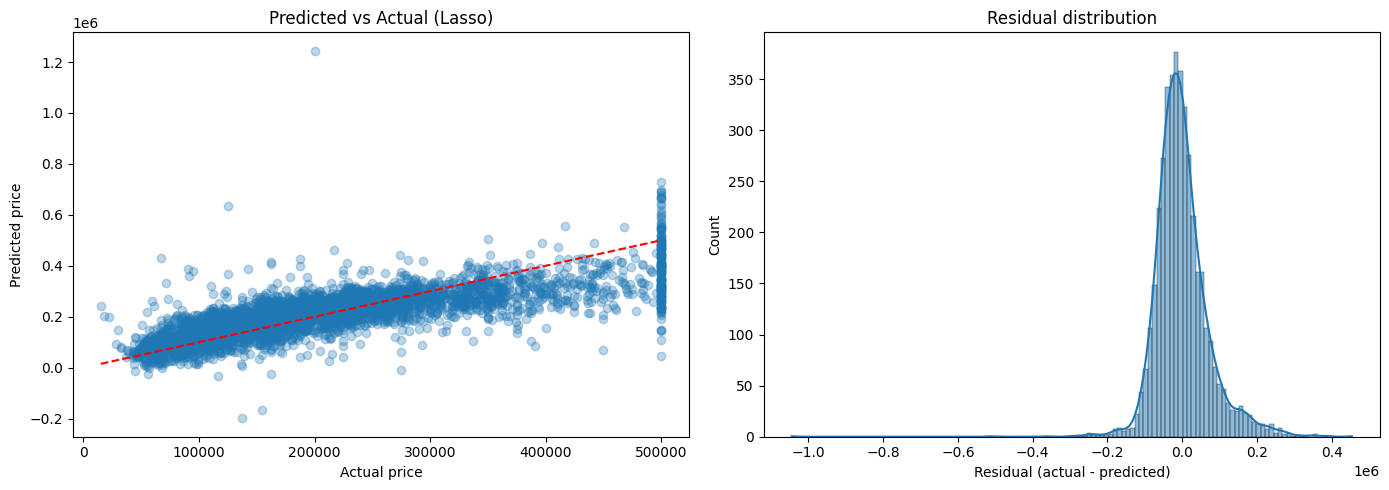

In [9]:
best_name = results.sort_values("RMSE").iloc[0]["Model"]
best_model = models[best_name]
pred = best_model.predict(X_test_s)
residuals = y_test - pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Predicted vs Actual
axes[0].scatter(y_test, pred, alpha=0.3)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
axes[0].set_xlabel("Actual price")
axes[0].set_ylabel("Predicted price")
axes[0].set_title(f"Predicted vs Actual ({best_name})")

# 2. Residual distribution
sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set_xlabel("Residual (actual - predicted)")
axes[1].set_title("Residual distribution")

plt.tight_layout()
plt.show()